# Capacity of spiking and discrete classifiers: progress report

We compare the classification capacity alpha_c = P/N of three models:

1. **Perceptron**: classic reference with exactly known capacity alpha_c = 2.
2. **Tempotron** (Gütig & Sompolinsky 2006): a spiking neuron that classifies spatiotemporal spike patterns.
3. **Multi-perceptron**: a discrete-time version of the tempotron, built from perceptrons with an OR rule over sub-patterns.

All experiments save their results in `results/`; running the notebook again loads them instead of recomputing.

**Key results.** Sections 1 and 2 reproduce known capacities numerically: the perceptron reaches $\alpha_c \approx 1.97$ (theory: 2, Cover 1965), and the
tempotron learns 75 % of datasets at $\alpha = 3.5$, so far consistent with the predicted $\alpha_c \approx 3.68$ (Rubin et al. 2010). Runs at $\alpha = 3.6$–$3.8$, which bracket the predicted capacity, are in progress. In the trained tempotron, output spikes are driven almost entirely by the inputs in the preceding 20 ms. Section 3 therefore introduces the *multi-perceptron*: a perceptron with an OR rule over $K$ binary sub-patterns, whose numbers of active afferents follow those 20 ms windows. Our hypothesis is that the multi-perceptron behaves as a discrete version of the tempotron. Consistent with this, its capacity grows from the perceptron value at $K = 1$ ($\alpha_c \approx 1.92$) to $\alpha_c \approx 3.4$ at $K = 300$, approaching the tempotron's. Because the multi-perceptron is simpler to analyse, it may help explain which input statistics determine the tempotron's capacity.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom
import importlib

import config as cfg
import experiments as ex
import perceptron as pc
import tempotron as tp
import multi_perceptron as mpc

## 1. Perceptron

### Model

The perceptron receives a binary input pattern $x \in \{0, 1\}^N$, where each
input is active ($x_i = 1$) with probability $f = 0.5$, and fires if the
weighted sum reaches the threshold:

$$\text{output} = \begin{cases} 1 & \text{if } w \cdot x \geq \theta \\ 0 & \text{otherwise} \end{cases}$$

We use $\theta = 0$ (no bias). The task: given $P$ random patterns with random
labels $y^\mu \in \{0, 1\}$, find weights $w$ that classify all of them
correctly.

### Learning rule

Patterns are presented one at a time in random order. On an error, the weights
move towards (missed label 1) or away from (wrong spike on label 0) the pattern:

$$w \leftarrow w \pm \lambda\, x^\mu$$

Correct patterns cause no update. An epoch without errors means all patterns
are learned. By the perceptron convergence theorem, this rule finds a solution
whenever one exists.

In [2]:
N_pc, f_pc, theta_pc = cfg.PC_N, cfg.PC_F, cfg.PC_THETA
lr_pc, w_std_pc = cfg.PC_LR, cfg.PC_W_STD

P_pc = cfg.PC_SINGLE_P                      # patterns for the single training run (alpha = 1.6)
max_epochs_pc = cfg.PC_SINGLE_MAX_EPOCHS
seeds_pc = cfg.PC_SINGLE_SEEDS

### Data

Each pattern consists of $N$ independent binary inputs, each active with
probability $f = 0.5$; labels are balanced (exactly $P/2$ of each).

X: (800, 500), labels 1 / 0: 400 / 400, mean input = 0.5008 (expected 0.5)


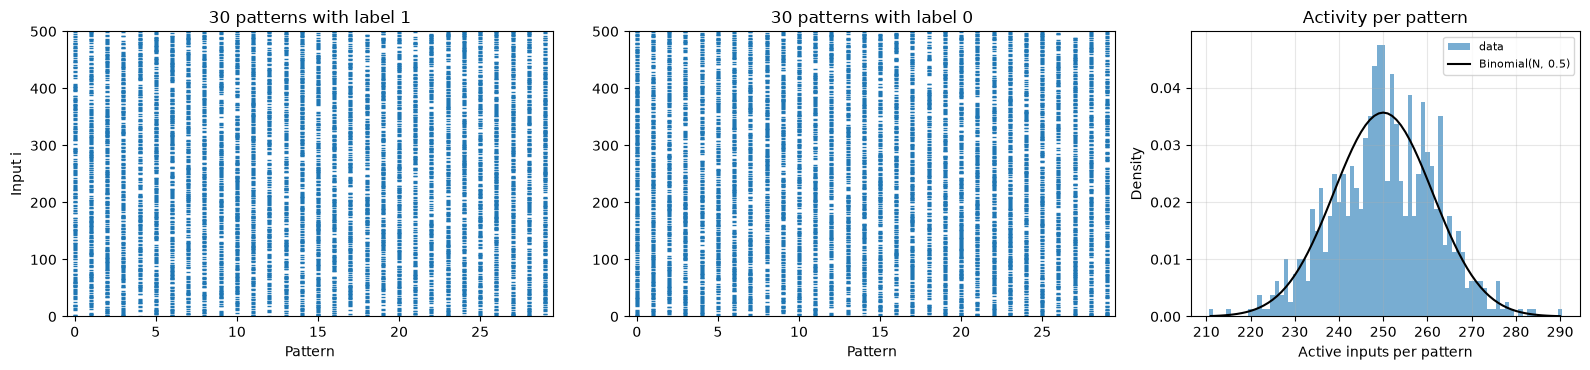

In [3]:
X_pc, y_pc = pc.make_dataset(N_pc, P_pc, np.random.default_rng(seeds_pc["data"]), f=f_pc)
print(f"X: {X_pc.shape}, labels 1 / 0: {y_pc.sum()} / {P_pc - y_pc.sum()}, "
      f"mean input = {X_pc.mean():.4f} (expected {f_pc})")

n_show = 30                                        # patterns per label shown
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 1, 0.8]})

for ax, label in zip(axes[:2], [1, 0]):
    idx = np.flatnonzero(y_pc == label)[:n_show]
    cols, inputs = np.nonzero(X_pc[idx].T)        # (input i, column) of every active entry
    ax.scatter(inputs, cols, marker="_", s=12, lw=1)
    ax.set_xlim(-0.5, n_show - 0.5)
    ax.set_ylim(0, N_pc)
    ax.set_xlabel("Pattern")
    ax.set_title(f"{n_show} patterns with label {label}")
axes[0].set_ylabel("Input i")

# Number of active inputs per pattern vs. Binomial(N, f)
n_active = X_pc.sum(axis=1)
k = np.arange(n_active.min(), n_active.max() + 1)
axes[2].hist(n_active, bins=np.arange(k[0] - 0.5, k[-1] + 1.5), density=True, alpha=0.6, label="data")
axes[2].plot(k, binom.pmf(k, N_pc, f_pc), "k-", label=f"Binomial(N, {f_pc:g})")
axes[2].set_xlabel("Active inputs per pattern")
axes[2].set_ylabel("Density")
axes[2].set_title("Activity per pattern")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Loaded single_model-perceptron_N-500_P-800_f-0.5.npz
Converged: True after 291 epochs, errors with final weights: 0


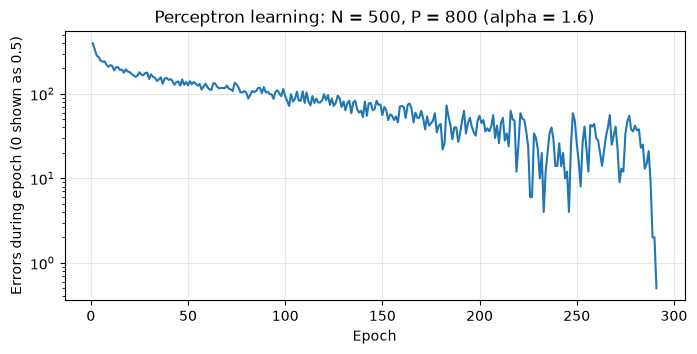

In [4]:
def train_single_pc():
    w0 = pc.init_weights(N_pc, np.random.default_rng(seeds_pc["init"]), std=w_std_pc)
    w, history, converged = pc.train(
        X_pc, y_pc, lr_pc, max_epochs_pc, np.random.default_rng(seeds_pc["order"]), w0,
        theta=theta_pc, verbose=0,
    )
    return dict(w=w, history=np.array(history), converged=converged)

res_pc = ex.cached_run(cfg.pc_single_name(), train_single_pc)
history_pc = res_pc["history"]

print(f"Converged: {bool(res_pc['converged'])} after {len(history_pc)} epochs, "
      f"errors with final weights: {pc.count_errors(res_pc['w'], X_pc, y_pc, theta_pc)}")

plt.figure(figsize=(8, 3.5))
plt.plot(np.arange(1, len(history_pc) + 1), np.maximum(history_pc, 0.5))
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Errors during epoch (0 shown as 0.5)")
plt.title(f"Perceptron learning: N = {N_pc}, P = {P_pc} (alpha = {P_pc / N_pc:.1f})")
plt.grid(alpha=0.3)
plt.show()

### Capacity measurement

For each load $\alpha = P/N$, we train on 10 independent datasets and record
the fraction learned within `max_epochs`. Since the perceptron rule always
finds an existing solution, this fraction should follow Cover's separability
probability, provided `max_epochs` is large enough. Near $\alpha = 2$ the
learning time grows strongly; a measured curve below Cover's curve there would
indicate that `max_epochs` is too small.

In [5]:
# Capacity scan: computes missing loads, loads those already in results/ (here or by a script)
df_cap_pc = ex.run_scan(
    cfg.pc_capacity_name(),
    [dict(alpha=a) for a in cfg.PC_CAP_ALPHAS],
    cfg.pc_capacity_run,
)

summary_pc = ex.summarize(df_cap_pc, "alpha")
summary_pc["cover"] = [binom.cdf(N_pc - 1, ex.even_P(a, N_pc) - 1, 0.5) for a in summary_pc.index]
display(summary_pc[["n", "frac_converged", "cover", "median"]].round(3))

alpha_est_pc, note_pc = ex.estimate_crossing(summary_pc.index, summary_pc["frac_converged"])
print(f"Measured capacity: {note_pc} (theory: alpha_c = 2)")

{'alpha': 1.6}: already done, skipped
{'alpha': 1.8}: already done, skipped
{'alpha': 1.9}: already done, skipped
{'alpha': 1.96}: already done, skipped
{'alpha': 2.0}: already done, skipped
{'alpha': 2.04}: already done, skipped
{'alpha': 2.1}: already done, skipped
{'alpha': 2.2}: already done, skipped
{'alpha': 2.4}: already done, skipped


,n,frac_converged,cover,median
alpha,,,,
1.60,10,1.0,1.000,207.0
1.80,10,1.0,1.000,919.5
1.90,10,0.7,0.948,2481.0
1.96,10,0.7,0.739,3359.0
2.00,10,0.1,0.500,11919.0
2.04,10,0.0,0.265,NaN
2.10,10,0.0,0.061,NaN
2.20,10,0.0,0.001,NaN
2.40,10,0.0,0.000,NaN


Measured capacity: crossing at 1.973 (theory: alpha_c = 2)


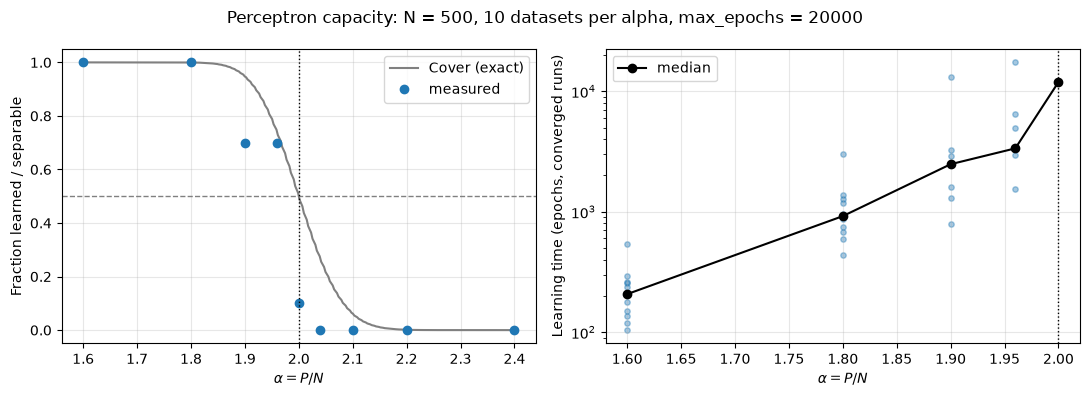

In [6]:
alpha_fine = np.linspace(min(cfg.PC_CAP_ALPHAS), max(cfg.PC_CAP_ALPHAS), 300)
cover_fine = [binom.cdf(N_pc - 1, int(round(a * N_pc)) - 1, 0.5) for a in alpha_fine]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(alpha_fine, cover_fine, color="gray", label="Cover (exact)")
axes[0].plot(summary_pc.index, summary_pc["frac_converged"], "o", color="C0", label="measured")
axes[0].axhline(0.5, color="gray", ls="--", lw=1)
axes[0].axvline(2.0, color="k", ls=":", lw=1)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_ylabel("Fraction learned / separable")
axes[0].legend()

conv = df_cap_pc[df_cap_pc["converged"]]
axes[1].scatter(conv["alpha"], conv["epochs"], alpha=0.4, s=15)
axes[1].plot(summary_pc.index, summary_pc["median"], "o-", color="k", label="median")
axes[1].axvline(2.0, color="k", ls=":", lw=1)
axes[1].set_yscale("log")
axes[1].set_ylabel("Learning time (epochs, converged runs)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel(r"$\alpha = P/N$")
    ax.grid(alpha=0.3)
fig.suptitle(f"Perceptron capacity: N = {N_pc}, {cfg.PC_CAP_N_DATASETS} datasets per alpha, "
             f"max_epochs = {cfg.PC_CAP_MAX_EPOCHS}")
plt.tight_layout()
plt.show()

### Result

The analysis agrees with the predicted capacity.

## 2. Tempotron

### Model

The tempotron (Gütig & Sompolinsky 2006) is a leaky integrate-and-fire neuron that classifies spatiotemporal spike patterns. Each of the $N$ afferents fires one spike at time $t_i$ within a pattern of duration $T$. The membrane potential is a weighted sum of postsynaptic potentials:

$$V(t) = \sum_i w_i\, K(t - t_i), \qquad K(s) = V_0 \left(e^{-s/\tau_m} - e^{-s/\tau_s}\right) \text{ for } s \geq 0,$$

with membrane and synaptic time constants $\tau_m = 10$ ms and $\tau_s = \tau_m / 4$, and $V_0$ normalizing the kernel maximum to 1. The neuron fires if $V(t)$ reaches the threshold $\theta = 1$ at any time during the pattern. After the first output spike, all later inputs are shunted.

The tempotron should fire for patterns with label 1 and stay silent for label 0. Compared to the perceptron, the decision depends not only on *which* afferents are active, but on *when* they fire.

### Learning rule

On an error, the weights are changed according to the contribution of each afferent to the potential at the time $t_{\max}$ of its maximum:

$$\Delta w_i = \pm \lambda \sum_{t_i < t_{\max}} K(t_{\max} - t_i) + \mu\, \Delta w_i^{\text{prev}},$$

with $+$ for a missed label-1 pattern and $-$ for a wrong spike on a label-0 pattern.

The learning rate decreases over the learning epochs $l = 1, 2, \dots$ (Gütig & Sompolinsky 2009):

$$\lambda_l = \frac{\lambda_{\text{ini}}}{1 + (l - 1)/\tau_{\text{decay}}},$$

with initial learning rate $\lambda_{\text{ini}} = 10^{-4} V_0$. Large steps early on speed up learning; smaller steps later allow fine adjustments close to a solution. For $\tau_{\text{decay}} \to \infty$ the learning rate is constant, as in the original 2006 paper.

### Numerics

$V(t)$, the output decision and $t_{\max}$ are computed by exact integration: between two input spikes, $V$ is a sum of two exponentials whose maximum is known in closed form, so no time grid is needed.

In [ ]:
# --- Shared parameters (from config.py, also used by run_capacity_tempotron.py) ---
N_tp, T_tp, theta_tp = cfg.TP_N, cfg.TP_T, cfg.TP_THETA
tau_m_tp, tau_s_tp, V0_tp = cfg.TP_TAU_M, cfg.TP_TAU_S, cfg.TP_V0
lr_tp, mu_tp, tau_decay_tp, w_std_tp = cfg.TP_LR, cfg.TP_MU, cfg.TP_TAU_DECAY, cfg.TP_W_STD

# --- Single training run  ---
P_tp = cfg.TP_SINGLE_P
max_epochs_tp = cfg.TP_SINGLE_MAX_EPOCHS
seeds_tp = cfg.TP_SINGLE_SEEDS

print(f"N = {N_tp}, T = {T_tp} ms, tau_m = {tau_m_tp} ms, tau_s = {tau_s_tp} ms")
print(f"V0 = {V0_tp:.4f}, lr_ini = {lr_tp:.2e}, mu = {mu_tp}, tau_decay = {tau_decay_tp}")

N = 500, T = 500.0 ms, tau_m = 10.0 ms, tau_s = 2.5 ms
V0 = 2.1165, lr_ini = 2.12e-04, mu = 0.99, tau_decay = 2000


### Data

Each afferent fires exactly one spike per pattern, at a time drawn uniformly
from $[0, T)$; labels are balanced. The figure shows the spike pattern of
three example patterns and the postsynaptic kernel $K$.

X: (1000, 500), labels 1 / 0: 500 / 500


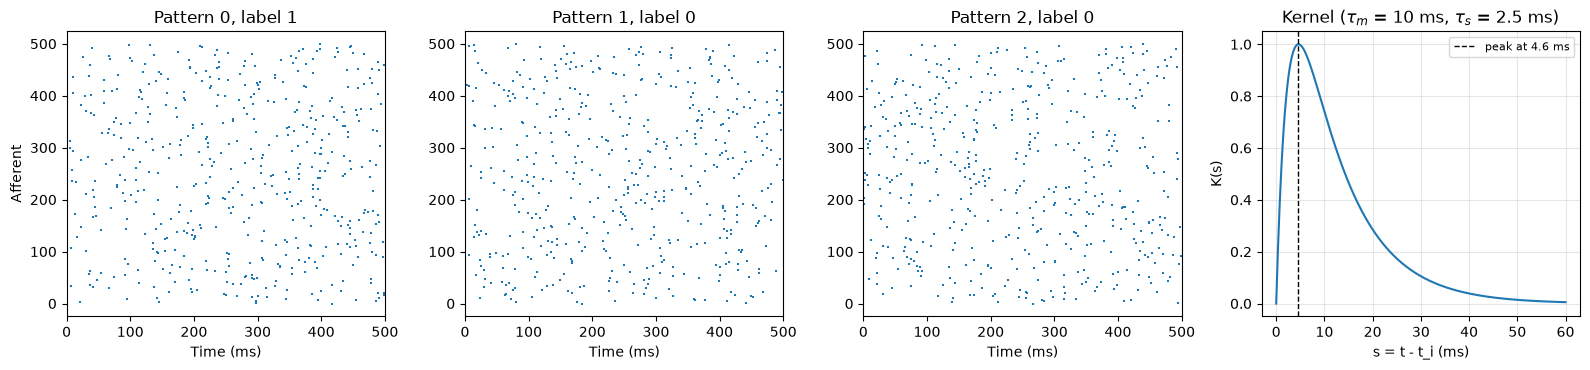

In [8]:
X_tp, y_tp = tp.make_dataset(N_tp, P_tp, T_tp, np.random.default_rng(seeds_tp["data"]))
data_tp = tp.prepare_exact(X_tp, T_tp, tau_m_tp, tau_s_tp)
print(f"X: {X_tp.shape}, labels 1 / 0: {y_tp.sum()} / {P_tp - y_tp.sum()}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, p in zip(axes[:3], range(3)):
    ax.scatter(X_tp[p], np.arange(N_tp), marker="|", s=4)
    ax.set_xlim(0, T_tp)
    ax.set_xlabel("Time (ms)")
    ax.set_title(f"Pattern {p}, label {y_tp[p]}")
axes[0].set_ylabel("Afferent")

s = np.linspace(0, 60, 500)
s_peak = tau_m_tp * tau_s_tp / (tau_m_tp - tau_s_tp) * np.log(tau_m_tp / tau_s_tp)
axes[3].plot(s, tp.kernel(s, tau_m_tp, tau_s_tp))
axes[3].axvline(s_peak, color="k", ls="--", lw=1, label=f"peak at {s_peak:.1f} ms")
axes[3].set_xlabel("s = t - t_i (ms)")
axes[3].set_ylabel("K(s)")
axes[3].set_title(f"Kernel ($\\tau_m$ = {tau_m_tp:g} ms, $\\tau_s$ = {tau_s_tp:g} ms)")
axes[3].legend(fontsize=8)
axes[3].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Choice of the time constant

How fast does the tempotron learn for different membrane time constants? We
vary $\tau_m$ with a fixed ratio $\tau_s = \tau_m / 4$ and measure the learning
time at $\alpha = 2$ on the same datasets. Since $V_0$ depends only on the
ratio $\tau_m / \tau_s$, the learning rate $\lambda = 10^{-4} V_0$ is the same
for all $\tau_m$: only the time scale of the kernel changes.

In [9]:
from functools import partial

df_tau = ex.run_scan(
    cfg.tempotron_tau_scan_name(),
    [dict(tau_m=t) for t in cfg.TP_TAU_SCAN_TAUS],
    partial(cfg.tempotron_tau_scan_run, n_jobs=-2),
)
summary_tau = ex.summarize(df_tau, "tau_m")
display(summary_tau[["n", "frac_converged", "median", "mean", "sem"]].round(2))

{'tau_m': 5.0}: already done, skipped
{'tau_m': 7.5}: already done, skipped
{'tau_m': 10.0}: already done, skipped
{'tau_m': 12.5}: already done, skipped
{'tau_m': 15.0}: already done, skipped
{'tau_m': 20.0}: already done, skipped
{'tau_m': 25.0}: already done, skipped
{'tau_m': 50.0}: already done, skipped
{'tau_m': 75.0}: already done, skipped


,n,frac_converged,median,mean,sem
tau_m,,,,,
5.0,10,1.0,421.0,426.20,96.18
7.5,10,1.0,112.0,108.30,9.49
10.0,10,1.0,117.5,115.20,7.02
12.5,10,1.0,100.0,103.60,7.79
15.0,10,1.0,94.5,96.40,7.69
20.0,10,1.0,114.0,109.10,8.52
25.0,10,1.0,126.5,125.90,12.71
50.0,10,1.0,141.0,165.40,28.79
75.0,10,0.9,393.0,740.78,231.15


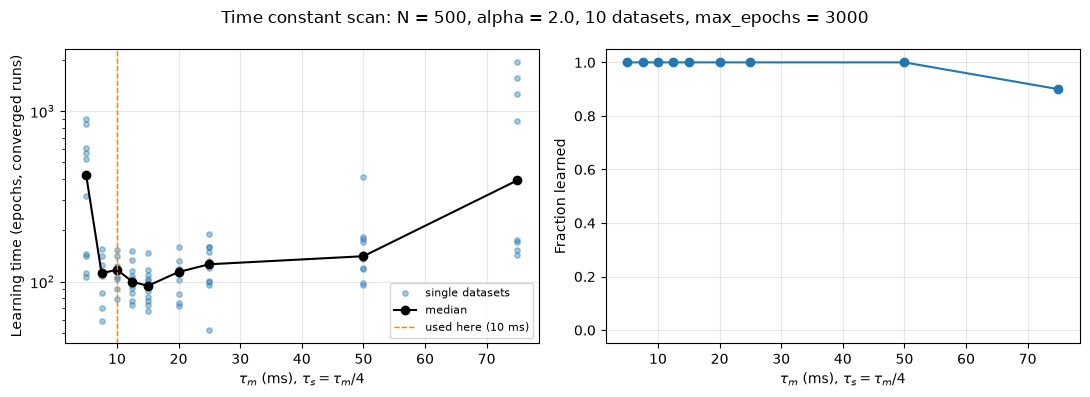

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
conv = df_tau[df_tau["converged"]]
axes[0].scatter(conv["tau_m"], conv["epochs"], alpha=0.4, s=15, label="single datasets")
axes[0].plot(summary_tau.index, summary_tau["median"], "o-", color="k", label="median")
axes[0].axvline(tau_m_tp, color="C1", ls="--", lw=1, label=f"used here ({tau_m_tp:g} ms)")
axes[0].set_yscale("log")
axes[0].set_ylabel("Learning time (epochs, converged runs)")
axes[0].legend(fontsize=8)

axes[1].plot(summary_tau.index, summary_tau["frac_converged"], "o-")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("Fraction learned")
for ax in axes:
    ax.set_xlabel(r"$\tau_m$ (ms), $\tau_s = \tau_m / 4$")
    ax.grid(alpha=0.3)
fig.suptitle(f"Time constant scan: N = {N_tp}, alpha = {cfg.TP_TAU_SCAN_ALPHA}, "
             f"{cfg.TP_TAU_SCAN_N_DATASETS} datasets, max_epochs = {cfg.TP_TAU_SCAN_MAX_EPOCHS}")
plt.tight_layout()
plt.show()

### Choice of the learning rate

With $\tau_m$ fixed, we vary the initial learning rate $\lambda_{\text{ini}}$
as a multiple of the paper value $10^{-4} V_0$ and measure the learning time at
$\alpha = 2$. With momentum $\mu$, the effective step size is roughly
$\lambda / (1 - \mu)$, i.e. 100 times larger for $\mu = 0.99$: too small
learning rates make learning slow, too large ones make the weights oscillate.

In [11]:
df_lr = ex.run_scan(
    cfg.tempotron_lr_scan_name(),
    [dict(lr_factor=f) for f in cfg.TP_LR_SCAN_FACTORS],
    partial(cfg.tempotron_lr_scan_run, n_jobs=-2),
)
summary_lr = ex.summarize(df_lr, "lr_factor")
display(summary_lr[["n", "frac_converged", "median", "mean", "sem"]].round(2))

{'lr_factor': 0.25}: already done, skipped
{'lr_factor': 0.5}: already done, skipped
{'lr_factor': 1.0}: already done, skipped
{'lr_factor': 2.0}: already done, skipped
{'lr_factor': 4.0}: already done, skipped
{'lr_factor': 8.0}: already done, skipped


,n,frac_converged,median,mean,sem
lr_factor,,,,,
0.25,10,1.0,184.0,187.1,15.63
0.50,10,1.0,132.5,139.0,14.70
1.00,10,1.0,117.5,115.2,7.02
2.00,10,1.0,105.0,107.6,5.91
4.00,10,1.0,118.0,118.6,5.39
8.00,10,0.5,203.0,248.4,62.13


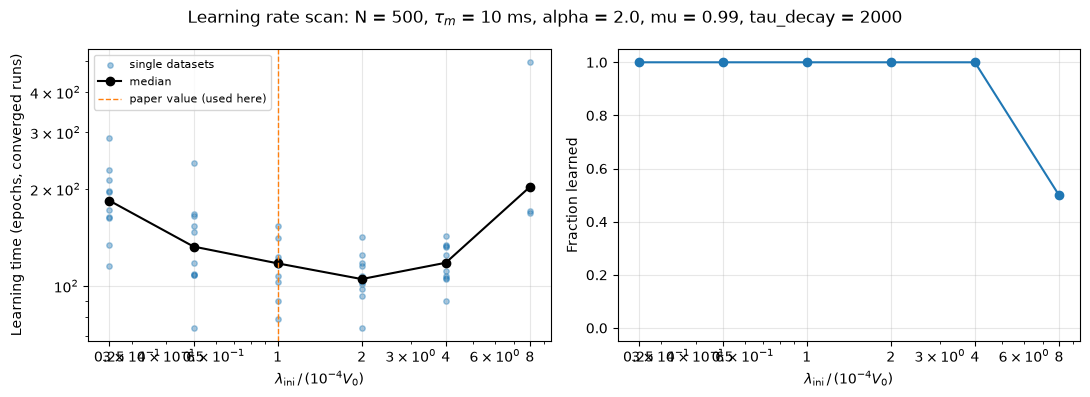

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
conv = df_lr[df_lr["converged"]]
axes[0].scatter(conv["lr_factor"], conv["epochs"], alpha=0.4, s=15, label="single datasets")
axes[0].plot(summary_lr.index, summary_lr["median"], "o-", color="k", label="median")
axes[0].axvline(1.0, color="C1", ls="--", lw=1, label="paper value (used here)")
axes[0].set_yscale("log")
axes[0].set_ylabel("Learning time (epochs, converged runs)")
axes[0].legend(fontsize=8)

axes[1].plot(summary_lr.index, summary_lr["frac_converged"], "o-")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("Fraction learned")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(cfg.TP_LR_SCAN_FACTORS)
    ax.set_xticklabels([f"{f:g}" for f in cfg.TP_LR_SCAN_FACTORS])
    ax.set_xlabel(r"$\lambda_{\mathrm{ini}} \,/\, (10^{-4} V_0)$")
    ax.grid(alpha=0.3)
fig.suptitle(f"Learning rate scan: N = {N_tp}, $\\tau_m$ = {tau_m_tp:g} ms, "
             f"alpha = {cfg.TP_LR_SCAN_ALPHA}, mu = {mu_tp}, tau_decay = {tau_decay_tp}")
plt.tight_layout()
plt.show()

### Single training run

Loaded single_model-tempotron_N-500_P-1000_tau_m-10_mu-0.99_decay-2000.npz
Converged: True after 86 epochs, errors with final weights: 0


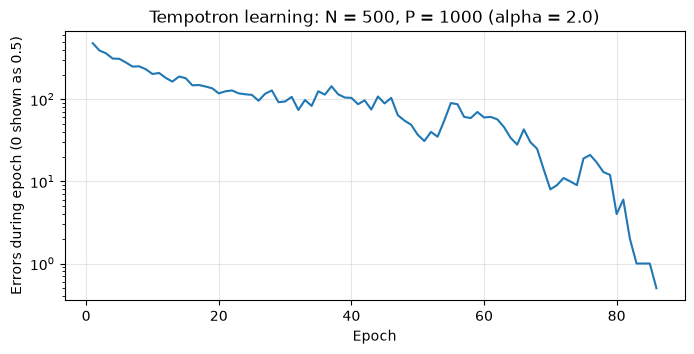

In [13]:
def train_single_tp():
    w0 = tp.init_weights(N_tp, np.random.default_rng(seeds_tp["init"]), std=w_std_tp)
    w, history, converged = tp.train_decay_exact(
        data_tp, y_tp, theta_tp, lr_ini=lr_tp, mu=mu_tp, max_epochs=max_epochs_tp,
        rng=np.random.default_rng(seeds_tp["order"]), w_init=w0,
        tau_decay=tau_decay_tp, verbose=0,
    )
    return dict(w=w, w0=w0, history=np.array(history), converged=converged)

res_tp = ex.cached_run(
    ex.make_name("single", model="tempotron", N=N_tp, P=P_tp, tau_m=tau_m_tp, mu=mu_tp,
                 decay=tau_decay_tp),
    train_single_tp,
)
history_tp = res_tp["history"]
print(f"Converged: {bool(res_tp['converged'])} after {len(history_tp)} epochs, "
      f"errors with final weights: {tp.count_errors_exact(res_tp['w'], data_tp, y_tp, theta_tp)}")

plt.figure(figsize=(8, 3.5))
plt.plot(np.arange(1, len(history_tp) + 1), np.maximum(history_tp, 0.5))
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Errors during epoch (0 shown as 0.5)")
plt.title(f"Tempotron learning: N = {N_tp}, P = {P_tp} (alpha = {P_tp / N_tp:.1f})")
plt.grid(alpha=0.3)
plt.show()

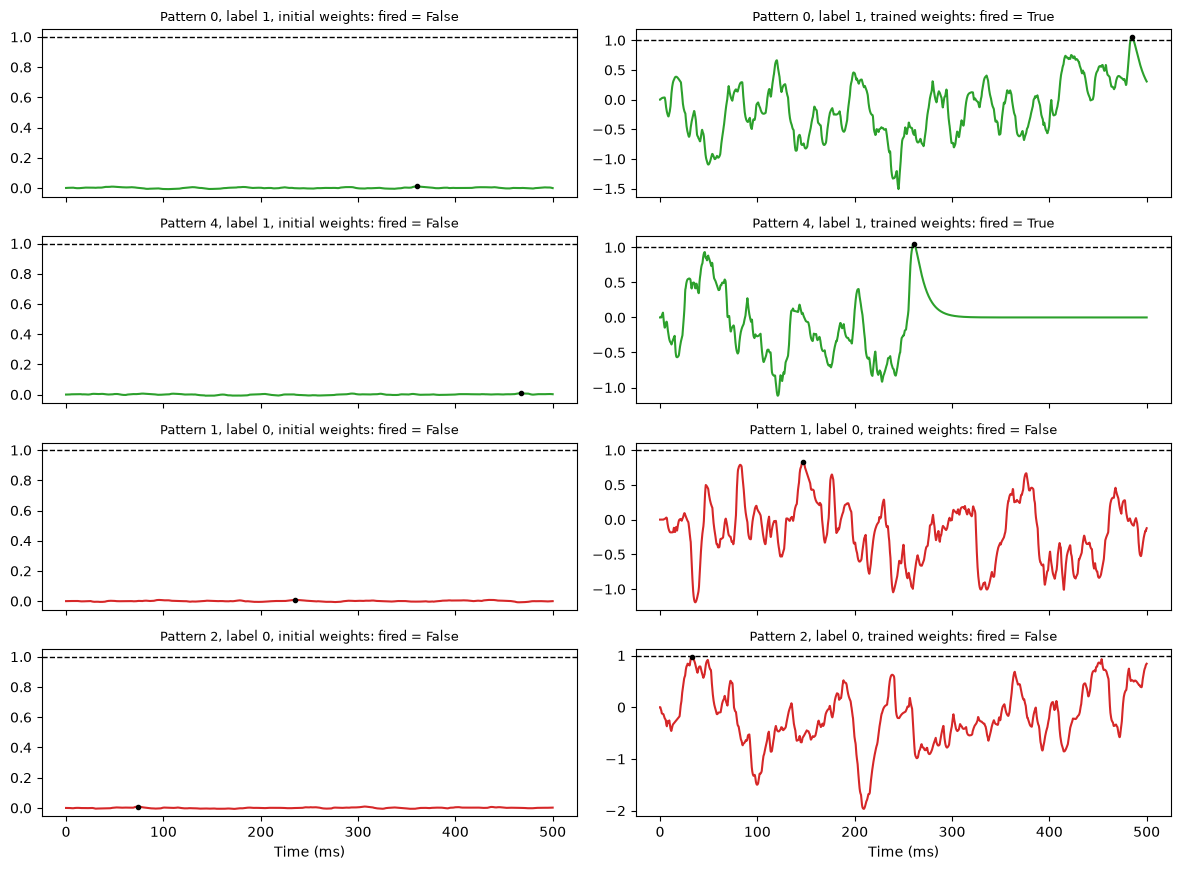

In [14]:
show = np.concatenate([np.flatnonzero(y_tp == 1)[:2], np.flatnonzero(y_tp == 0)[:2]])
t_eval = np.linspace(0, T_tp, 2001)

fig, axes = plt.subplots(len(show), 2, figsize=(12, 2.2 * len(show)), sharex=True)
for row, p in enumerate(show):
    for col, (w_, name) in enumerate([(res_tp["w0"], "initial"), (res_tp["w"], "trained")]):
        spiked, _, t_max, V_max = tp.forward_exact(data_tp, p, w_, theta_tp)
        V = tp.potential_exact(data_tp, p, w_, t_eval, theta_tp)
        ax = axes[row, col]
        ax.plot(t_eval, V, color="C2" if y_tp[p] == 1 else "C3")
        ax.plot(t_max, V_max, "o", ms=3, color="k")
        ax.axhline(theta_tp, color="k", ls="--", lw=1)
        ax.set_title(f"Pattern {p}, label {y_tp[p]}, {name} weights: fired = {spiked}", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

### What makes the trained tempotron fire?

For every output spike of the trained tempotron, we look at the input spikes
before it: how much of the potential at the spike time comes from recent
inputs, and how many inputs arrive in the last 20 ms. As a baseline, we count
the inputs in random 20 ms windows of the same patterns.

In [15]:
window_tp = cfg.TP_WINDOW                                  # ms before the output spike
lags = np.linspace(1, 100, 100)                            # window lengths for the explained fraction
rng_baseline = np.random.default_rng(0)
n_random = 100                                             # random windows per pattern (baseline)

w_tr = res_tp["w"]
count_spike, count_random, explained = [], [], []
lags_in_window, w_in_window = [], []
for p in range(P_tp):
    # Baseline: a random window of the same length in the same pattern
    t_r = rng_baseline.uniform(window_tp, T_tp, size=n_random)
    in_window = (X_tp[p][None, :] > t_r[:, None] - window_tp) & (X_tp[p][None, :] <= t_r[:, None])
    count_random.extend(in_window.sum(axis=1))

    t_sp = tp.spike_time_exact(data_tp, p, w_tr, theta_tp)
    if t_sp is None:
        continue
    lag = t_sp - X_tp[p]
    before = lag > 0
    count_spike.append(np.sum(before & (lag <= window_tp)))

    in_window = before & (lag <= window_tp)
    lags_in_window.append(lag[in_window])
    w_in_window.append(w_tr[in_window])

    # Fraction of V(t_spike) contributed by inputs within the last L ms, for every L
    contrib = w_tr[before] * tp.kernel(lag[before], tau_m_tp, tau_s_tp)
    total = contrib.sum()                          # = V(t_spike) = theta
    explained.append([contrib[lag[before] <= L].sum() / total for L in lags])

count_spike, count_random = np.array(count_spike), np.array(count_random)
explained = np.array(explained)
lags_in_window = np.concatenate(lags_in_window)
w_in_window = np.concatenate(w_in_window)

mean_window_tp, std_window_tp = count_spike.mean(), count_spike.std()
i20 = np.argmin(np.abs(lags - window_tp))

ex.save_json(dict(
    mean=float(mean_window_tp), std=float(std_window_tp), n_spikes=int(len(count_spike)),
    window=window_tp,
    random_mean=float(count_random.mean()), random_std=float(count_random.std()),
    explained_fraction=float(explained[:, i20].mean()),
), cfg.window_stats_name())

print(f"Output spikes analysed: {len(count_spike)}")
print(f"Inputs in the {window_tp:g} ms before an output spike: "
      f"{mean_window_tp:.1f} ± {std_window_tp:.1f}")
print(f"Inputs in random {window_tp:g} ms windows:            "
      f"{count_random.mean():.1f} ± {count_random.std():.1f}  "
      f"(expected {N_tp * window_tp / T_tp:.1f} ± "
      f"{np.sqrt(N_tp * window_tp / T_tp * (1 - window_tp / T_tp)):.1f})")
print(f"Fraction of V(t_spike) from the last {window_tp:g} ms: "
      f"{explained[:, i20].mean():.2f} ± {explained[:, i20].std():.2f}")

Saved window_stats_model-tempotron_N-500_P-1000_tau_m-10_lr-0.000211653_mu-0.99_decay-2000_window-20.json
Output spikes analysed: 500
Inputs in the 20 ms before an output spike: 21.9 ± 4.5
Inputs in random 20 ms windows:            20.0 ± 4.4  (expected 20.0 ± 4.4)
Fraction of V(t_spike) from the last 20 ms: 1.02 ± 0.09


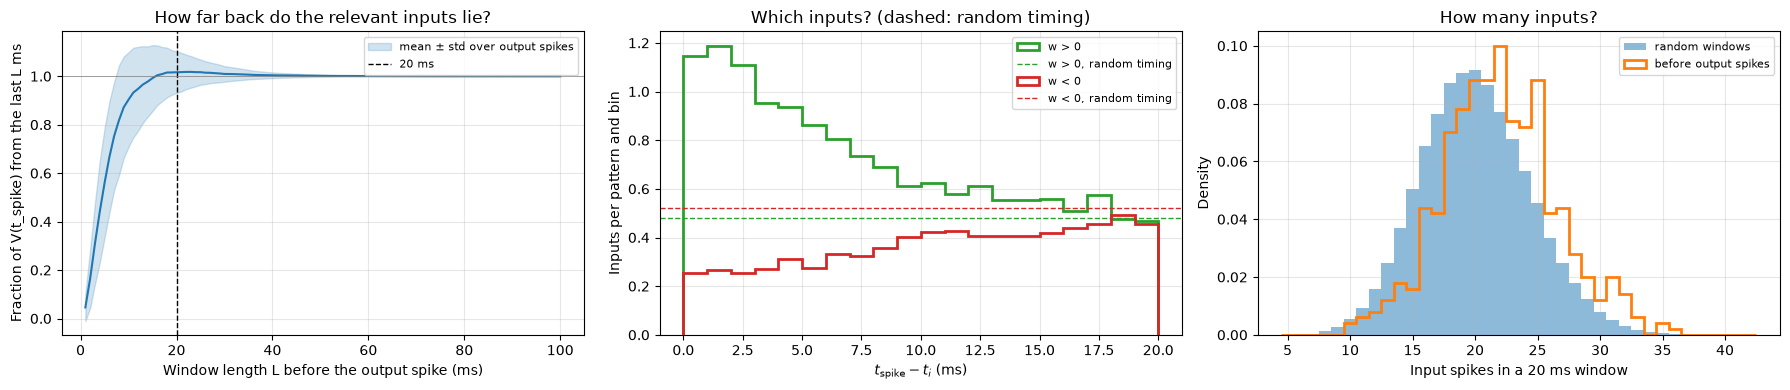

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# (1) Fraction of V(t_spike) from the last L ms
m, s = explained.mean(axis=0), explained.std(axis=0)
axes[0].plot(lags, m, color="C0")
axes[0].fill_between(lags, m - s, m + s, color="C0", alpha=0.2, label="mean ± std over output spikes")
axes[0].axvline(window_tp, color="k", ls="--", lw=1, label=f"{window_tp:g} ms")
axes[0].axhline(1.0, color="gray", lw=0.5)
axes[0].set_xlabel("Window length L before the output spike (ms)")
axes[0].set_ylabel("Fraction of V(t_spike) from the last L ms")
axes[0].set_title("How far back do the relevant inputs lie?")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# (2) Excitatory and inhibitory inputs vs. lag, compared to random timing
n_spikes = len(count_spike)
lag_bins = np.linspace(0, window_tp, 21)               # 1 ms bins
expected = N_tp * (lag_bins[1] - lag_bins[0]) / T_tp   # inputs per bin without structure
frac_exc = (w_tr > 0).mean()
for sign, name, color, frac in [(1, "w > 0", "C2", frac_exc), (-1, "w < 0", "C3", 1 - frac_exc)]:
    sel = np.sign(w_in_window) == sign
    axes[1].hist(lags_in_window[sel], bins=lag_bins, weights=np.full(sel.sum(), 1 / n_spikes),
                 histtype="step", lw=2, color=color, label=name)
    axes[1].axhline(expected * frac, color=color, ls="--", lw=1, label=f"{name}, random timing")
axes[1].set_xlabel(r"$t_{\mathrm{spike}} - t_i$ (ms)")
axes[1].set_ylabel("Inputs per pattern and bin")
axes[1].set_title("Which inputs? (dashed: random timing)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

# (3) Number of inputs in the window: before output spikes vs. random windows
count_bins = np.arange(min(count_spike.min(), count_random.min()) - 0.5,
                       max(count_spike.max(), count_random.max()) + 1.5)
axes[2].hist(count_random, bins=count_bins, density=True, alpha=0.5, label="random windows")
axes[2].hist(count_spike, bins=count_bins, density=True, histtype="step", lw=2,
             label="before output spikes")
axes[2].set_xlabel(f"Input spikes in a {window_tp:g} ms window")
axes[2].set_ylabel("Density")
axes[2].set_title("How many inputs?")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Capacity measurement

As for the perceptron, we train on 10 independent datasets per load
$\alpha = P/N$ and record the fraction learned within `max_epochs`, using the
learning rule and parameters of the 2006 paper. Since the tempotron's solution
space is not convex, there is no convergence theorem: the measured value is
the capacity reached *by this learning rule*, which is also what the paper
reports.

In [29]:
alpha_paper = 3.68            # for T = 500 ms and tau_m = 10 ms, roughly ln(ln(100)) / (2 ln(2)) + 2.58 ≈ 3.68

# Computed by run_capacity_tempotron.py; here only loaded (missing loads would be computed on one core)
df_cap_tp = ex.run_scan(
    cfg.tempotron_capacity_name(),
    [dict(alpha=a) for a in cfg.TP_CAP_ALPHAS],
    cfg.tempotron_capacity_run,
)
summary_tp = ex.summarize(df_cap_tp, "alpha")
display(summary_tp[["n", "frac_converged", "median"]].round(3))

alpha_est_tp, note_tp = ex.estimate_crossing(summary_tp.index, summary_tp["frac_converged"])
print(f"Measured capacity: {note_tp} (paper: about {alpha_paper})")

{'alpha': 2.4}: already done, skipped
{'alpha': 2.8}: already done, skipped
{'alpha': 3.0}: already done, skipped
{'alpha': 3.2}: already done, skipped
{'alpha': 3.4}: already done, skipped
{'alpha': 3.5}: already done, skipped


,n,frac_converged,median
alpha,,,
2.4,20,1.00,280.5
2.8,20,1.00,972.5
3.0,20,1.00,1739.5
3.2,20,1.00,3495.5
3.4,20,0.90,7136.0
3.5,20,0.75,8487.0


Measured capacity: crossing above the scanned range (> 3.5) (paper: about 3.68)


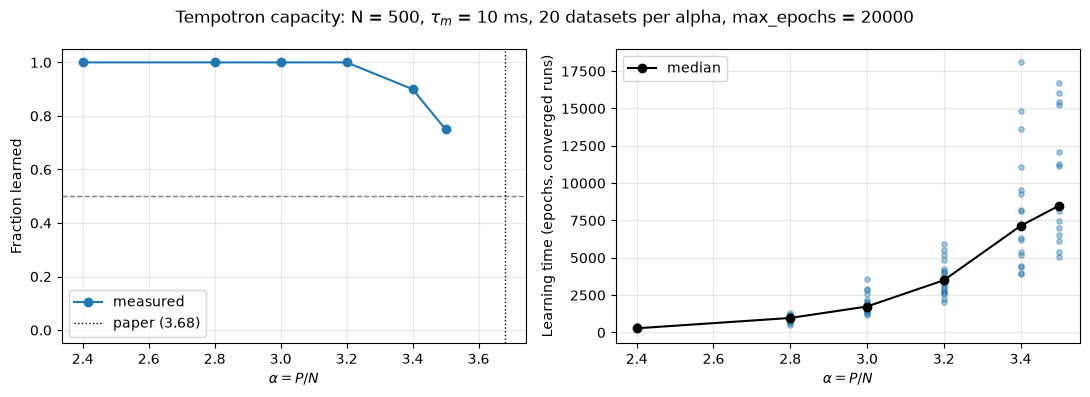

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(summary_tp.index, summary_tp["frac_converged"], "o-", color="C0", label="measured")
axes[0].axhline(0.5, color="gray", ls="--", lw=1)
axes[0].axvline(alpha_paper, color="k", ls=":", lw=1, label=f"paper ({alpha_paper})")
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_ylabel("Fraction learned")
axes[0].legend()

conv = df_cap_tp[df_cap_tp["converged"]]
axes[1].scatter(conv["alpha"], conv["epochs"], alpha=0.4, s=15)
axes[1].plot(summary_tp.index, summary_tp["median"], "o-", color="k", label="median")
# axes[1].set_yscale("log")
axes[1].set_ylabel("Learning time (epochs, converged runs)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel(r"$\alpha = P/N$")
    ax.grid(alpha=0.3)
fig.suptitle(f"Tempotron capacity: N = {N_tp}, $\\tau_m$ = {tau_m_tp:g} ms, "
             f"{cfg.TP_CAP_N_DATASETS} datasets per alpha, max_epochs = {cfg.TP_CAP_MAX_EPOCHS}")
plt.tight_layout()
plt.show()

### Result

Learning at $\alpha = 2$ is fast over a broad range of parameters: the median learning time varies little for $\tau_m$ between 7.5 and 25 ms and for $\lambda_{\text{ini}}$ between 0.5 and 4 times the value of Gütig & Sompolinsky (2006); the values used here ($\tau_m = 10$ ms, $\lambda_{\text{ini}} = 10^{-4} V_0$) lie within this range. All datasets are learned up to $\alpha = 3.2$ and 75 % at $\alpha = 3.5$, consistent with the predicted capacity $\alpha_c \approx 3.68$ (Rubin et al. 2010). Runs at $\alpha = 3.6$–$3.8$, which bracket this value, are in progress.

## 3. Multi-perceptron: a discrete model of the tempotron's decision

### Motivation

In the trained tempotron (section 2), the potential at an output spike is almost entirely due to the inputs in the preceding 20 ms: they account for 102 ± 9 % of $V(t_{\text{spike}})$ (earlier inputs contribute slightly negatively on net). These windows contain 21.9 ± 4.5 input spikes, only slightly more than random 20 ms windows (20.0 ± 4.4). Spike-triggering windows are thus distinguished mainly by *which* afferents are active, not by *how many*.

We therefore model a pattern as a set of $K$ such windows: $K$ binary sub-patterns $x_k \in \{0, 1\}^N$, each with a random set of active afferents, whose number is drawn from the window statistics measured in section 2.

### Model

The multi-perceptron computes $V_k = w \cdot x_k$ for every sub-pattern and fires if at least one of them reaches the threshold (OR rule):

$$\text{output} = 1 \iff \max_k V_k \geq \theta.$$

$K = 1$ is an ordinary perceptron with sparse binary inputs.

### Learning rule

As for the tempotron, with the binary sub-pattern in place of the kernel: on a wrong spike, the weights of the afferents active in the first sub-pattern that reached the threshold are lowered (analogous to shunting); on a missed label-1 pattern, those of the sub-pattern with the highest potential are raised (analogous to $t_{\max}$), both with momentum $\mu$.

### Question

How does the capacity depend on the number of windows $K$? A 500 ms pattern contains $T / 20\,\text{ms} = 25$ non-overlapping windows, but the tempotron can place its window freely. In the extreme value treatment of Rubin et al. (2010), the output is decided by the maximum of $V(t)$, which behaves like the maximum of about $T / \sqrt{\tau_m \tau_s} = 100$ independent samples. We therefore expect the multi-perceptron to approach the tempotron's capacity for $K$ between about 25 and 100.

In [31]:
importlib.reload(cfg)          # picks up the window statistics saved in section 2

# --- Shared parameters (from config.py, also used by run_capacity_multi_perceptron.py) ---
N_mpc, theta_mpc = cfg.MPC_N, cfg.MPC_THETA
mean_active_mpc, std_active_mpc = cfg.MPC_MEAN_ACTIVE, cfg.MPC_STD_ACTIVE
lr_mpc, mu_mpc, credit_mpc, w_std_mpc = cfg.MPC_LR, cfg.MPC_MU, cfg.MPC_CREDIT, cfg.MPC_W_STD

# --- Single training run (this notebook only) ---
K_mpc = 8                     # sub-patterns per pattern
P_mpc = 1000                  # patterns (alpha = 2)
max_epochs_mpc = 5000
seeds_mpc = dict(data=100, init=110, order=120)

print(f"Window statistics: N({mean_active_mpc}, {std_active_mpc}^2), {cfg.MPC_WINDOW_SOURCE}")
if "mean_window_tp" in globals():
    print(f"Measured in section 2:  {mean_window_tp:.1f} ± {std_window_tp:.1f}")

Window statistics: N(21.9, 4.5^2), measured (section 2)
Measured in section 2:  21.9 ± 4.5


### Data

X: (1000, 8, 500), labels 1 / 0: 500 / 500, active per sub-pattern: 21.97 ± 4.50


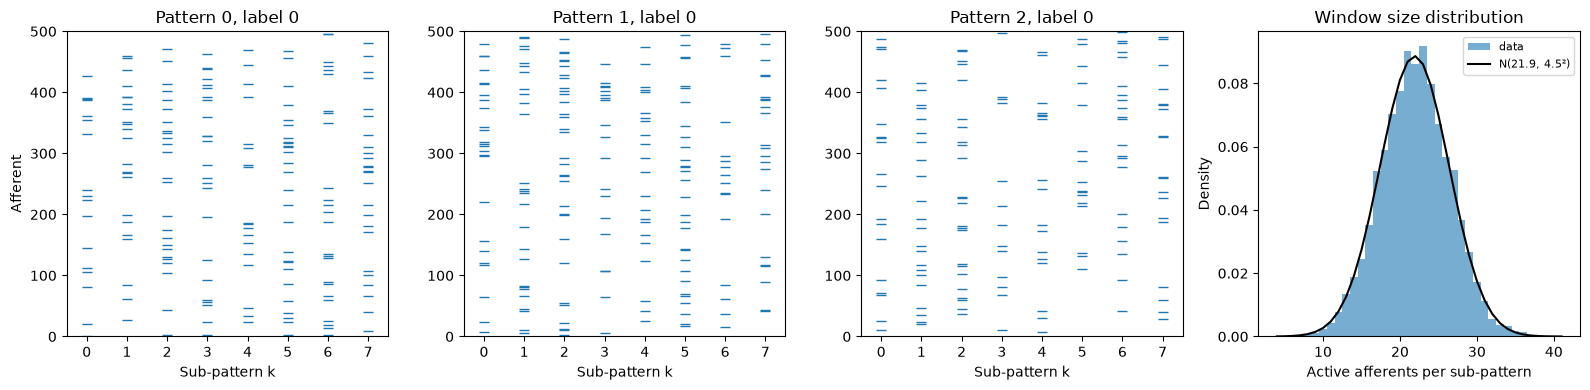

In [32]:
X_mpc, y_mpc, n_active_mpc = mpc.make_dataset(
    N_mpc, P_mpc, K_mpc, np.random.default_rng(seeds_mpc["data"]),
    mean_active=mean_active_mpc, std_active=std_active_mpc,
)
print(f"X: {X_mpc.shape}, labels 1 / 0: {y_mpc.sum()} / {P_mpc - y_mpc.sum()}, "
      f"active per sub-pattern: {n_active_mpc.mean():.2f} ± {n_active_mpc.std():.2f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, p in zip(axes[:3], range(3)):
    ks, aff = np.nonzero(X_mpc[p])
    ax.scatter(ks, aff, marker="_", s=60, lw=1)
    ax.set_xticks(range(K_mpc))
    ax.set_xlim(-0.5, K_mpc - 0.5)
    ax.set_ylim(0, N_mpc)
    ax.set_xlabel("Sub-pattern k")
    ax.set_title(f"Pattern {p}, label {y_mpc[p]}")
axes[0].set_ylabel("Afferent")

m = np.arange(n_active_mpc.min(), n_active_mpc.max() + 1)
pdf = np.exp(-(m - mean_active_mpc) ** 2 / (2 * std_active_mpc ** 2)) / (std_active_mpc * np.sqrt(2 * np.pi))
axes[3].hist(n_active_mpc.ravel(), bins=np.arange(m[0] - 0.5, m[-1] + 1.5), density=True,
             alpha=0.6, label="data")
axes[3].plot(m, pdf, "k-", label=f"N({mean_active_mpc:g}, {std_active_mpc:g}²)")
axes[3].set_xlabel("Active afferents per sub-pattern")
axes[3].set_ylabel("Density")
axes[3].set_title("Window size distribution")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Choice of learning rate and momentum

Since the multi-perceptron's solution space is not convex, the capacity we
measure depends on the learning rule. We therefore tune the learning rate
$\lambda$ and momentum $\mu$ at $K = 25$ and a load close to capacity
($\alpha = 2.8$), using the fraction of learned datasets and the learning time
as criteria.

In [33]:
tasks_tune = [dict(lr=lr, mu=mu, dataset=s)
              for lr in cfg.MPC_TUNE_LRS for mu in cfg.MPC_TUNE_MUS
              for s in range(cfg.MPC_TUNE_N_DATASETS)]
df_tune = ex.run_tasks(cfg.mpc_tune_name(), tasks_tune, cfg.mpc_tune_task, n_jobs=-2)

summary_tune = ex.summarize(df_tune, ["lr", "mu"])
display(summary_tune[["n", "frac_converged", "median"]].round(2))

200 of 200 tasks already done, 0 to run


n  frac_converged  median
lr    mu                              
0.001 0.00  10             0.0     NaN
      0.90  10             0.0     NaN
      0.99  10             1.0   741.5
0.002 0.00  10             0.0     NaN
      0.90  10             0.0     NaN
      0.99  10             1.0   569.5
0.005 0.00  10             0.0     NaN
      0.90  10             0.8  2015.0
      0.99  10             1.0   638.0
0.010 0.00  10             0.0     NaN
      0.90  10             1.0   858.5
      0.99  10             1.0   692.0
0.020 0.00  10             0.0     NaN
      0.90  10             0.9   853.0
      0.99  10             1.0   475.5
0.050 0.90  10             1.0   860.5
      0.99  10             1.0   551.0
0.100 0.90  10             1.0   708.0
      0.99  10             1.0  1207.5
0.200 0.90  10             0.9   924.0
      0.99  10             0.9   507.0
0.500 0.90  10             1.0   759.5
      0.99  10             1.0   581.5
1.000 0.90  10             0.9   734.0
      0.99  10             1.0   572.5

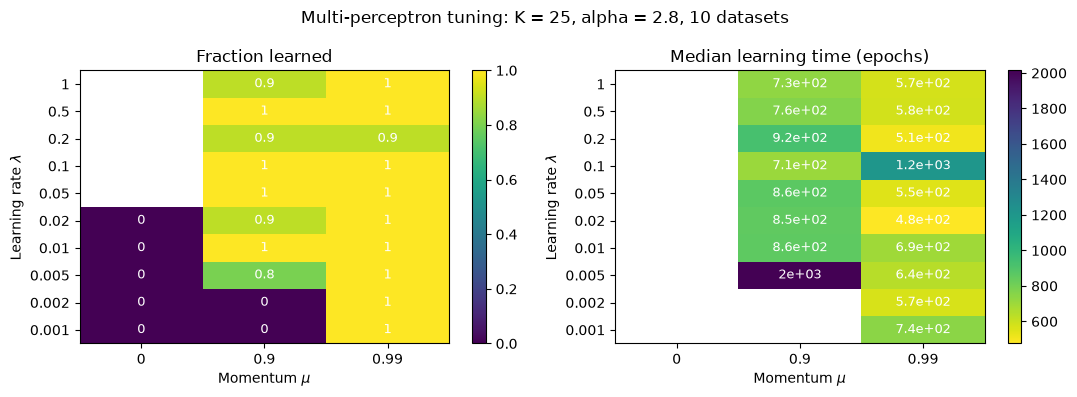

In [34]:
frac = summary_tune["frac_converged"].unstack("mu")
med = summary_tune["median"].unstack("mu")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, table, title, cmap in [(axes[0], frac, "Fraction learned", "viridis"),
                               (axes[1], med, "Median learning time (epochs)", "viridis_r")]:
    im = ax.imshow(table.values, cmap=cmap, aspect="auto", origin="lower")
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels([f"{m:g}" for m in table.columns])
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels([f"{lr:g}" for lr in table.index])
    ax.set_xlabel(r"Momentum $\mu$")
    ax.set_ylabel(r"Learning rate $\lambda$")
    ax.set_title(title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, "–" if np.isnan(v) else f"{v:.2g}", ha="center", va="center",
                    color="white", fontsize=9)
    fig.colorbar(im, ax=ax)
fig.suptitle(f"Multi-perceptron tuning: K = {cfg.MPC_TUNE_K}, alpha = {cfg.MPC_TUNE_ALPHA}, "
             f"{cfg.MPC_TUNE_N_DATASETS} datasets")
plt.tight_layout()
plt.show()

Loaded single_model-multi_perceptron_N-500_P-1000_K-8_mean-21.9_lr-0.02_mu-0.99_credit-first.npz
Converged: True after 75 epochs, errors with final weights: 0


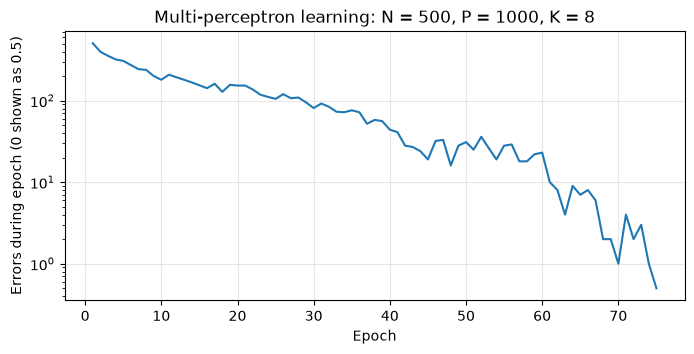

In [35]:
def train_single_mpc():
    w0 = mpc.init_weights(N_mpc, np.random.default_rng(seeds_mpc["init"]), std=w_std_mpc)
    w, history, converged = mpc.train(
        X_mpc, y_mpc, theta_mpc, lr_mpc, max_epochs_mpc,
        np.random.default_rng(seeds_mpc["order"]), w0,
        mu=mu_mpc, credit=credit_mpc, verbose=0,
    )
    return dict(w=w, history=np.array(history), converged=converged)

res_mpc = ex.cached_run(
    ex.make_name("single", model="multi_perceptron", N=N_mpc, P=P_mpc, K=K_mpc,
                 mean=mean_active_mpc, lr=lr_mpc, mu=mu_mpc, credit=credit_mpc),
    train_single_mpc,
)
history_mpc = res_mpc["history"]
print(f"Converged: {bool(res_mpc['converged'])} after {len(history_mpc)} epochs, "
      f"errors with final weights: {mpc.count_errors(res_mpc['w'], X_mpc, y_mpc, theta_mpc)}")

plt.figure(figsize=(8, 3.5))
plt.plot(np.arange(1, len(history_mpc) + 1), np.maximum(history_mpc, 0.5))
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Errors during epoch (0 shown as 0.5)")
plt.title(f"Multi-perceptron learning: N = {N_mpc}, P = {P_mpc}, K = {K_mpc}")
plt.grid(alpha=0.3)
plt.show()

### Capacity as a function of the number of windows

For each $K$, we determine the capacity of several datasets by bisection over
$P$ (nested datasets, resolution 0.02 in $\alpha$), keeping the window
statistics fixed. The scan is run with `run_capacity_multi_perceptron.py`;
here we only load its results.

In [36]:
importlib.reload(cfg)

tasks_K = [dict(K=K, dataset=s) for K in sorted(cfg.MPC_K_LIST, reverse=True)
           for s in range(cfg.MPC_K_N_DATASETS)]

# Computes missing tasks; tasks already computed (here or by the script) are only loaded
df_K = ex.run_tasks(cfg.mpc_capacity_vs_K_name(), tasks_K, cfg.mpc_capacity_task, n_jobs=-2)

summary_K = df_K.groupby("K")["alpha_c"].agg(["mean", "std", "count"])
summary_K["sem"] = summary_K["std"] / np.sqrt(summary_K["count"])
display(summary_K.round(3))

60 of 60 tasks already done, 0 to run


,mean,std,count,sem
K,,,,
1,1.922,0.054,5,0.024
5,2.702,0.108,5,0.048
10,2.924,0.068,5,0.030
20,3.040,0.100,5,0.045
40,3.149,0.101,5,0.045
60,3.260,0.072,5,0.032
80,3.142,0.177,5,0.079
100,3.294,0.093,5,0.042
120,3.226,0.098,5,0.044


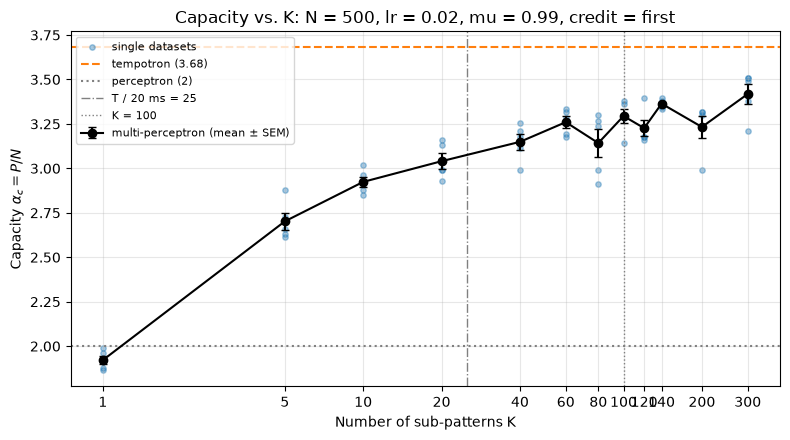

In [37]:
alpha_tp_ref = alpha_est_tp if np.isfinite(alpha_est_tp) else alpha_paper

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df_K["K"], df_K["alpha_c"], alpha=0.4, s=15, label="single datasets")
ax.errorbar(summary_K.index, summary_K["mean"], yerr=summary_K["sem"], fmt="o-", color="k",
            capsize=3, label="multi-perceptron (mean ± SEM)")
ax.axhline(alpha_tp_ref, color="C1", ls="--", label=f"tempotron ({alpha_tp_ref:.2f})")
ax.axhline(2.0, color="gray", ls=":", label="perceptron (2)")
ax.axvline(25, color="gray", ls="-.", lw=1, label="T / 20 ms = 25")
ax.axvline(100, color="gray", ls=":", lw=1, label="K = 100")
ax.set_xscale("log", base=2)
ax.set_xticks(cfg.MPC_K_LIST)
ax.set_xticklabels([str(k) for k in cfg.MPC_K_LIST])
ax.set_xlabel("Number of sub-patterns K")
ax.set_ylabel(r"Capacity $\alpha_c = P/N$")
ax.set_title(f"Capacity vs. K: N = {N_mpc}, lr = {lr_mpc:g}, mu = {mu_mpc}, credit = {credit_mpc}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Result

The capacity rises steeply from the perceptron value at $K = 1$ ($\alpha_c = 1.92 \pm 0.02$) to $\alpha_c \approx 3.0$ at $K = 20$, and then grows only slowly, roughly logarithmically in $K$ ($3.29 \pm 0.04$ at $K = 100$, $3.42 \pm 0.06$ at $K = 300$). In the expected range $K \approx 25$–$100$, the multi-perceptron thus reaches about 85–90 % of the tempotron's capacity, but not the full value. Possible reasons: (i) the sub-patterns are independent, while the tempotron's time windows overlap and are correlated; (ii) binary sub-patterns discard the spike timing within a window, which the kernel weights; (iii) "not learned within `max_epochs`" makes the measured capacity a lower bound, which also explains the outliers at $K = 80$ and $K = 200$. Which of these accounts for the gap is the subject of further analysis.